# Задание: Классификация самолетов (Военный или Гражданский) по фото

В этом Jupyter Notebook реализовано решение задачи классификации самолетов с использованием мультимодальных LLM (VLM) через Hugging Face Inference API.

In [10]:
# !pip install huggingface_hub pandas scikit-learn matplotlib seaborn pillow tqdm

import os
import base64
import time
import json
import pandas as pd
import numpy as np
from PIL import Image
from io import BytesIO
from tqdm import tqdm
from huggingface_hub import InferenceClient

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, 
    f1_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Настройка клиента и промпта
Замените `hf_ваш_токен_здесь` на ваш токен от Hugging Face (с правами на использование Inference Providers).

In [ ]:
HF_TOKEN = os.getenv("HF_TOKEN", "")
client = InferenceClient(api_key=HF_TOKEN)

# Используем две модели для сравнения
MODELS = {
    "Qwen2.5-VL-7B": "Qwen/Qwen2.5-VL-7B-Instruct",
    "Llama-3.2-11B-Vision": "meta-llama/Llama-3.2-11B-Vision-Instruct"
}

SYSTEM_PROMPT = """You are an aviation expert. Analyze the image of the aircraft and classify it as either "military" or "civilian".
Pay close attention to non-trivial cues:
- Tail numbers / registration codes (civilian prefixes like N-, RA-, G-, D- vs military serials/stars/roundels).
- Special equipment (radomes, refueling booms, hardpoints, sensors vs commercial airline liveries or private racing modifications).

Respond ONLY with a valid JSON object in this exact format:
{"label": "military" or "civilian", "confidence": 0.0 to 1.0, "reasoning": "short 1-sentence explanation"}"""

## 2. Вспомогательные функции (Кодирование и инференс)
Функция `encode_image_to_base64` переводит локальные изображения в формат, понятный API.

In [3]:
def encode_image_to_base64(image_path: str, max_size=(800, 800)) -> str:
    """Сжимает изображение и переводит в data URI base64."""
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail(max_size)
        buffered = BytesIO()
        img.save(buffered, format="JPEG", quality=85)
        img_str = base64.b64encode(buffered.getvalue()).decode("utf-8")
    return f"data:image/jpeg;base64,{img_str}"

def classify_aircraft(image_path: str, model_id: str) -> dict:
    """Отправляет изображение в VLM через HF InferenceClient и парсит ответ."""
    image_data_url = encode_image_to_base64(image_path)
    
    messages = [
        {
            "role": "user",
            "content": [
                {"type": "text", "text": SYSTEM_PROMPT},
                {"type": "image_url", "image_url": {"url": image_data_url}}
            ]
        }
    ]
    
    start_time = time.time()
    try:
        response = client.chat.completions.create(
            model=model_id,
            messages=messages,
            max_tokens=150,
            temperature=0.0
        )
        latency = round(time.time() - start_time, 2)
        raw_text = response.choices[0].message.content.strip()
        
        clean_text = raw_text.replace("```json", "").replace("```", "").strip()
        parsed = json.loads(clean_text)
        
        label = parsed.get("label", "unknown").lower().strip()
        if label not in ["military", "civilian"]:
            label = "military" if "military" in raw_text.lower() else "civilian"
            
        return {
            "pred_label": label,
            "reasoning": parsed.get("reasoning", ""),
            "latency_sec": latency,
            "error": None
        }
    except Exception as e:
        return {
            "pred_label": "error",
            "reasoning": str(e),
            "latency_sec": round(time.time() - start_time, 2),
            "error": str(e)
        }

## 3. Обработка датасета (30 фото)
Предполагается наличие файла `metadata.csv` со столбцами `filename`, `true_label`, `category`, `aircraft_name`.

In [16]:
df = pd.read_csv("dataset/metadata.csv") 
results = []

for idx, row in tqdm(df.iterrows(), total=len(df), desc="Оценка моделей"):
    img_path = os.path.join("dataset", row["filename"])
    row_res = row.to_dict()
    
    for short_name, model_id in MODELS.items():
        res = classify_aircraft(img_path, model_id)
        row_res[f"{short_name}_pred"] = res["pred_label"]
        row_res[f"{short_name}_reason"] = res["reasoning"]
        row_res[f"{short_name}_time"] = res["latency_sec"]
        time.sleep(1) # Защита от Rate Limit бесплатного тира HF
        
    results.append(row_res)

results_df = pd.DataFrame(results)
results_df.to_csv("evaluation_results.csv", index=False)
results_df.head()

Оценка моделей:   0%|          | 0/30 [00:00<?, ?it/s]2026-10-24 17:44:47,531 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Request"
2026-10-24 17:44:48,780 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Request"
Оценка моделей:   3%|▎         | 1/30 [00:03<01:27,  3.01s/it]2026-10-24 17:44:50,047 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Request"
2026-10-24 17:44:51,260 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Request"
Оценка моделей:   7%|▋         | 2/30 [00:05<01:15,  2.70s/it]2026-10-24 17:44:52,595 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Request"
2026-10-24 17:44:54,037 - INFO - httpx2 - HTTP Request: POST https://router.huggingface.co/v1/chat/completions "HTTP/1.1 400 Bad Req

FileNotFoundError: [Errno 2] No such file or directory: 'dataset\\11.jpg'

## 4. Подсчет и вывод метрик
Вычисляем Accuracy, Precision, Recall и F1-score (отдельно анализируем нетривиальные случаи).

In [14]:
def calculate_metrics(df: pd.DataFrame, model_prefix: str) -> dict:
    valid_df = df[df[f"{model_prefix}_pred"].isin(["military", "civilian"])]
    if len(valid_df) == 0:
        return {"Model": model_prefix}
        
    y_true = valid_df["true_label"]
    y_pred = valid_df[f"{model_prefix}_pred"]
    
    hard_df = valid_df[~valid_df["category"].isin(["basic_civilian", "basic_military"])]
    hard_acc = accuracy_score(hard_df["true_label"], hard_df[f"{model_prefix}_pred"]) if len(hard_df) > 0 else 0
    
    return {
        "Model": model_prefix,
        "Accuracy (All)": round(accuracy_score(y_true, y_pred), 3),
        "Accuracy (Hard Cases)": round(hard_acc, 3),
        "Precision (Military)": round(precision_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "Recall (Military)": round(recall_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "F1-Score": round(f1_score(y_true, y_pred, pos_label="military", zero_division=0), 3),
        "Avg Latency (s)": round(valid_df[f"{model_prefix}_time"].mean(), 2)
    }

metrics_list = [calculate_metrics(results_df, m) for m in MODELS.keys()]
metrics_table = pd.DataFrame(metrics_list).set_index("Model")
display(metrics_table)

Exception ignored in: <function tqdm.__del__ at 0x000001F96B1FE2A0>
Traceback (most recent call last):
  File "c:\Users\ilyar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\ilyar\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\notebook.py", line 279, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


NameError: name 'results_df' is not defined

## 5. Визуализация и матрицы ошибок

NameError: name 'results_df' is not defined

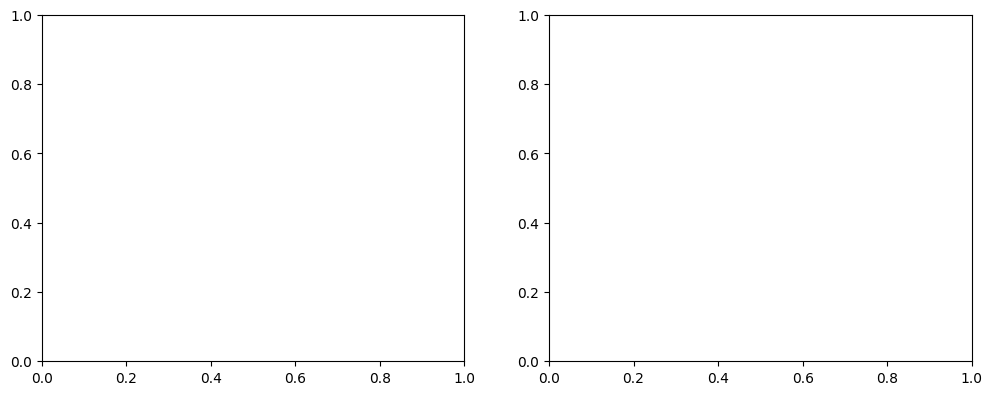

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
labels = ["civilian", "military"]

for ax, model_name in zip(axes, MODELS.keys()):
    valid_df = results_df[results_df[f"{model_name}_pred"].isin(labels)]
    if len(valid_df) == 0: continue
    cm = confusion_matrix(valid_df["true_label"], valid_df[f"{model_name}_pred"], labels=labels)
    
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels, ax=ax, cbar=False)
    ax.set_title(f"Confusion Matrix: {model_name}")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.show()